# Imports

In [12]:

import torch

# Check for GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [13]:
import pandas as pd
import numpy as np
import cv2
import os
import copy
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_v2_s
from torchvision.models import EfficientNet_V2_S_Weights
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

In [14]:
#setting seeds for reproducilibity

seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.backends.cudnn.deterministic = True

# Configuration

In [15]:
mean=[0.485, 0.456, 0.406]
std=[0.229, 0.224, 0.225]

device="cuda" if torch.cuda.is_available() else "cpu"
batch_size=8

# Exploratory Data Analysis

In [16]:
train_dir="C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Training/training_words"
val_dir="C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Validation/validation_words"
test_dir="C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Testing/testing_words"
train_label_filepth="C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Training/training_labels.csv"
val_label_filepth="C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Validation/validation_labels.csv"
test_label_filepth="C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Testing/testing_labels.csv"

In [17]:
df=pd.read_csv(train_label_filepth)
df.columns

Index(['IMAGE', 'MEDICINE_NAME', 'GENERIC_NAME'], dtype='object')

In [18]:
medicines=['Ace', 'Aceta', 'Alatrol', 'Amodis',
           'Cetisoft', 'Ketocon', 'Metro', 'Nidazyl', 'Rhinil', 'Paracetamol' ]

cls_to_label={k:v for k,v in zip(medicines,range(len(medicines)))}
label_to_cls={v:k for k,v in zip(medicines,range(len(medicines)))}

In [19]:
name=[]
height=[]
width=[]
for img_name in os.listdir(train_dir):
    img_path=os.path.join(train_dir,img_name)
    img=cv2.imread(img_path)
    
    name.append(img_name)
    height.append(img.shape[0])
    width.append(img.shape[1])

In [20]:
df_inter=pd.DataFrame({"name":name,
                       "height":height,
                       "width":width})

df_inter.head()

,name,height,width
0,1.png,81,132
1,10.png,24,66
2,100.png,248,430
3,101.png,248,430
4,102.png,248,430


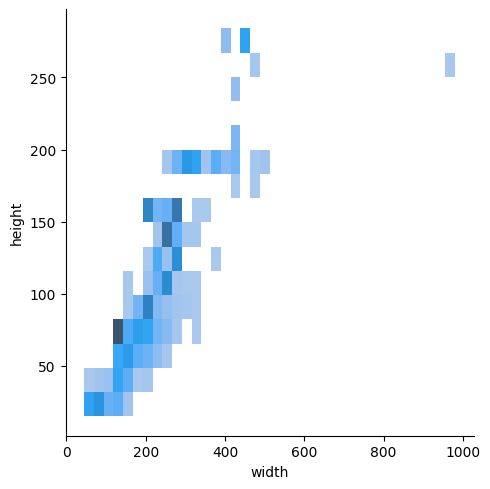

In [21]:
sns.displot(data=df_inter,x="width",y="height")

In [22]:
len(df_inter[(df_inter["height"]<75)&(df_inter["width"]<200)])

262

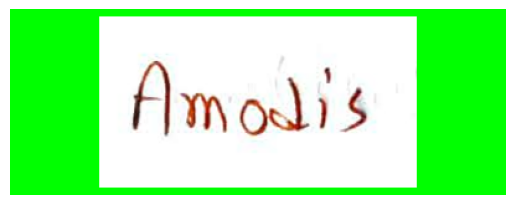

In [23]:
"""
padding small images to the dimension (75,200) in order to preserve information 
while resizing to (224,224) 
"""

img_pth=os.path.join(train_dir,"339.png")
img=cv2.imread(img_pth)
img_pad=cv2.copyMakeBorder(img,top=75-img.shape[0]//2,bottom=75-img.shape[0]//2,
                           left=200-img.shape[1]//2, right=200-img.shape[1]//2,
                           borderType=cv2.BORDER_CONSTANT,value=[0,255,0])
plt.imshow(img_pad);
plt.axis("off");

# Custom Dataset Class

In [24]:
transform=transforms.Compose([transforms.ToTensor(),
                              transforms.Resize(size=(256,256)),
                              transforms.Normalize(mean=mean,std=std)])

In [25]:
class Prescription(Dataset):
    def __init__(self,data_dir,label_pth,transform=None):
        super().__init__()
        self.data_dir=data_dir
        self.label_pth=label_pth
        self.transform=transform
        
        self.img_list=sorted(list(os.listdir(data_dir)))
        self.label_df=pd.read_csv(self.label_pth)
        
    def __len__(self):
        return len(self.img_list)
        
    def __getitem__(self,idx):
        img_name=self.img_list[idx]
        img_pth=os.path.join(self.data_dir,img_name)
        img=cv2.imread(img_pth)
        img=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
            
        if img.shape[0]<75:
            img=cv2.copyMakeBorder(img,top=75-img.shape[0]//2,
                                   bottom=75-img.shape[0]//2,
                                   left=0, right=0,
                                   borderType=cv2.BORDER_CONSTANT,
                                   value=[0,255,0])
                
        if img.shape[1]<200:
            img=cv2.copyMakeBorder(img,top=0,bottom=0,
                                   left=200-img.shape[1]//2,
                                   right=200-img.shape[1]//2,
                                   borderType=cv2.BORDER_CONSTANT,
                                   value=[0,255,0])
                
        medicine_cls=self.label_df.loc[self.label_df["IMAGE"]==img_name,
                                       "MEDICINE_NAME"].values[0]
        medicine_label=cls_to_label[str(medicine_cls)]
        
            
        label=torch.tensor(medicine_label,dtype=torch.int64)
            
        if self.transform is not None:
            img=self.transform(img)
                
        return img,label
                

# Dataset

In [26]:
train_ds=Prescription(train_dir,train_label_filepth,transform)
val_ds=Prescription(val_dir,val_label_filepth,transform)
test_ds=Prescription(test_dir,test_label_filepth,transform)

train_dl=DataLoader(train_ds,batch_size=batch_size,shuffle=True,
                    pin_memory=True if torch.cuda.is_available() else False)
val_dl=DataLoader(val_ds,batch_size=batch_size,shuffle=False,
                    pin_memory=True if torch.cuda.is_available() else False)
test_dl=DataLoader(test_ds,batch_size=batch_size,shuffle=False,
                    pin_memory=True if torch.cuda.is_available() else False)

# Data Visualization

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.008057998657226562..1.0000000236034394].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.053115898461357e-09..1.0000001308918].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.053115898461357e-09..1.000000114440918].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.053115898461357e-09..1.0000001308918].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.053115898461357e-09..1.0000001308918].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.053115898461357e-09..1.000000114440918].


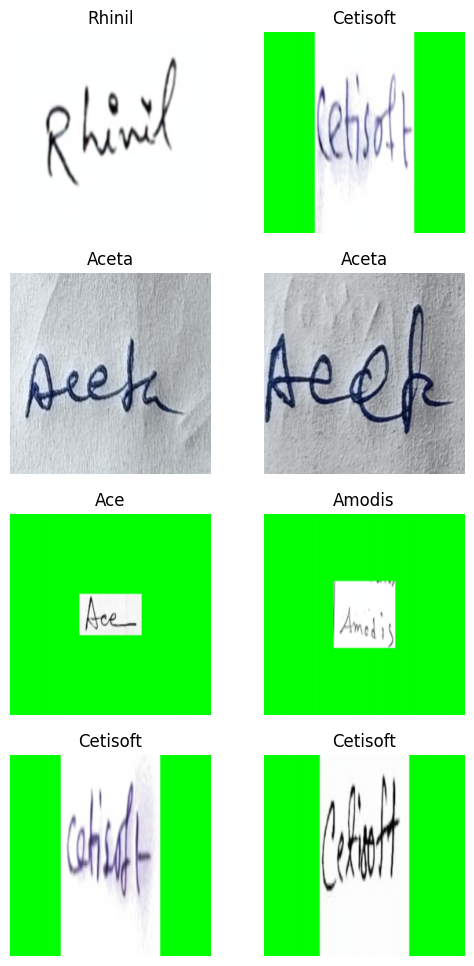

In [27]:
fig,axes=plt.subplots(4,2,figsize=(6,12))
ax=axes.flatten()
imgs,labels=next(iter(train_dl))

img=imgs[0]
for i,img in enumerate(imgs[:len(ax)]):
    imgp=np.transpose(img.numpy().copy(),(1,2,0))*std+mean
    ax[i].imshow(imgp)
    ax[i].set_title(label_to_cls[labels[i].item()])
    ax[i].axis("off")

# Training

In [28]:
class EarlyStopping():
    def __init__(self,min_delta,patience):
        self.min_delta=min_delta
        self.patience=patience
        self.counter=0
        self.best_validation_loss=float('inf')
        
    def __call__(self,validation_loss):
        if (validation_loss+self.min_delta)<self.best_validation_loss:
            self.best_validation_loss=validation_loss
            self.counter=0
        else:
            self.counter+=1
            if self.counter==self.patience:
                return True
            
        return False
        

In [29]:
def training(model,epochs,train_dl,val_dl,optimizer,loss_fn,weights_path):
    best_val_acc=0.0
    patience=10
    best_weights=copy.deepcopy(model.state_dict())
    loss_dict={"train_loss":[],"train_acc":[],"val_loss":[],"val_acc":[]}
    early_stopper=EarlyStopping(min_delta=0.05,patience=10)
    
    for epoch in range(epochs):
        
        train_loss=0.0
        train_acc=0.0
        train_len=len(train_dl.dataset)
        val_loss=0.0
        val_acc=0.0
        val_len=len(val_dl.dataset)
        
        model.train()
        for imgs,labels in train_dl:
            imgs,labels=imgs.to(device),labels.to(device)
            output=model(imgs)
            loss=loss_fn(output,labels)
            
            train_loss+=loss.item()
            pred_labels=output.argmax(dim=1)
            train_acc+=(labels==pred_labels).sum().item()
            
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            
        model.eval()
        with torch.no_grad():
            for imgs,labels in val_dl:
                imgs,labels=imgs.to(device),labels.to(device)
                output=model(imgs)
                loss=loss_fn(output,labels)
                
                val_loss+=loss.item()
                pred_labels=output.argmax(dim=1)
                val_acc+=(labels==pred_labels).sum().item()
            
        if val_acc>best_val_acc:
            best_val_acc=val_acc
            best_weights=copy.deepcopy(model.state_dict())
            print("Updating Best Model weights")
            
        loss_dict["train_loss"].append(train_loss/train_len)  
        loss_dict["train_acc"].append(train_acc/train_len)
        loss_dict["val_loss"].append(val_loss/val_len)  
        loss_dict["val_acc"].append(val_acc/val_len)
        
        print(f"{epoch+1}/{epochs}: Training\nloss: {train_loss/train_len} accuracy: {train_acc/train_len}")
        print(f"{epoch+1}/{epochs}: Evaluating\nloss: {val_loss/val_len} accuracy: {val_acc/val_len}") 
        print("*"*50,"\n")
        
        if early_stopper(val_loss/val_len):
            break
        
    torch.save(best_weights,weights_path)
    return loss_dict

# Model

In [30]:
def get_model(weights=None):
    model=efficientnet_v2_s(weights=weights)
    in_features=model.classifier[1].in_features
    model.classifier[1]=nn.Linear(in_features=in_features,out_features=len(medicines))
    model.to(device)
    
    return model

# Model Fine Tuning

In [31]:
weights=EfficientNet_V2_S_Weights.DEFAULT
model=get_model(weights)

In [32]:
froze_layers=["features.0","features.1","features.2","features.3","features.4"]

for names,parameters in model.named_parameters():
    if names[:10] in froze_layers:
        parameters.requires_grad=False
    else :
        parameters.requires_grad=True
        
parameters=[params for params in model.parameters() if params.requires_grad==True]

In [35]:
optimizer=optim.Adam(parameters,lr=3e-5,weight_decay=3e-4)
loss_fn=nn.CrossEntropyLoss(reduction="sum")
finetuning_weights_path="C:/Users/mdimr/Desktop/Final_Year_Project/finetuning_model.pth"

In [36]:
loss_dict=training(model,70,train_dl,val_dl,optimizer,loss_fn,
                   finetuning_weights_path)

Updating Best Model weights
1/70: Training
loss: 0.02121906749315952 accuracy: 0.9968421052631579
1/70: Evaluating
loss: 0.14574380577891133 accuracy: 0.97
************************************************** 

Updating Best Model weights
2/70: Training
loss: 0.013655691346349684 accuracy: 0.9989473684210526
2/70: Evaluating
loss: 0.09222260475275107 accuracy: 0.98
************************************************** 

3/70: Training
loss: 0.020195420532438314 accuracy: 0.9978947368421053
3/70: Evaluating
loss: 0.09357353593863081 accuracy: 0.98
************************************************** 

4/70: Training
loss: 0.017234853576182534 accuracy: 0.9968421052631579
4/70: Evaluating
loss: 0.07919411763228709 accuracy: 0.97
************************************************** 

5/70: Training
loss: 0.034012674566260295 accuracy: 0.9936842105263158
5/70: Evaluating
loss: 0.14934317340841516 accuracy: 0.97
************************************************** 

6/70: Training
loss: 0.029800367804

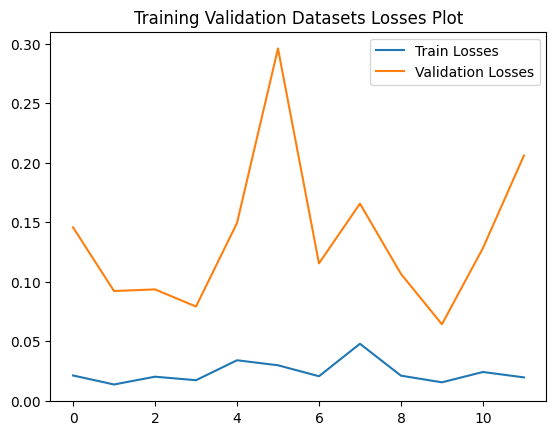

In [37]:
x=range(len(loss_dict['train_loss']))
sns.lineplot(x=x,y=loss_dict['train_loss'],label="Train Losses");
sns.lineplot(x=x,y=loss_dict['val_loss'],label="Validation Losses");
plt.title("Training Validation Datasets Losses Plot");
plt.legend();

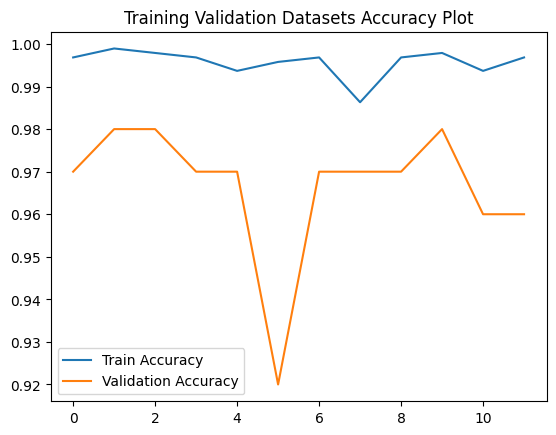

In [38]:
sns.lineplot(x=x,y=loss_dict['train_acc'],label="Train Accuracy");
sns.lineplot(x=x,y=loss_dict['val_acc'],label="Validation Accuracy");
plt.title("Training Validation Datasets Accuracy Plot");
plt.legend();

# Inference

In [40]:
model=get_model()
model.load_state_dict(torch.load("C:/Users/mdimr/Desktop/Final_Year_Project/finetuning_model.pth"))

<All keys matched successfully>

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.053115898461357e-09..1.0000001308918].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.053115898461357e-09..1.0000001308918].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.053115898461357e-09..1.0000001308918].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.053115898461357e-09..1.0000001308918].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.053115898461357e-09..1.0000001308918].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.053115898461357e-09..1.0000001308918].
Clipping input data to

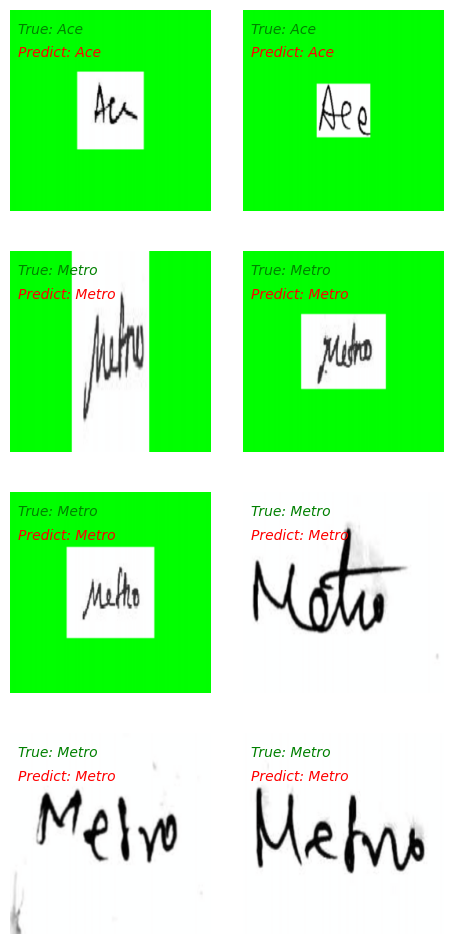

In [41]:
fig,axes=plt.subplots(4,2,figsize=(6,12))
plt.subplots_adjust(wspace=0)
ax=axes.flatten()

imgs,labels=next(iter(test_dl))
model.eval()
with torch.no_grad():
    imgs=imgs.to(device)
    output=model(imgs)

for i in range(imgs.shape[0]):
    pred_label=output[i].argmax(0)
    ax[i].imshow(imgs[i].permute(1,2,0).cpu().numpy()*std+mean)
    ax[i].text(10,30,"True: "+ label_to_cls[labels[i].item()],style ='italic',
               fontsize = 10, color ="green")
    ax[i].text(10,60,"Predict: "+ label_to_cls[labels[i].item()],style ='italic',
                fontsize = 10, color ="red")
    ax[i].axis("off")

# Evaluation

In [42]:
y_true=[]
y_pred=[]
model.eval()
with torch.no_grad():
    for j,(imgs,labels) in enumerate(test_dl):
        imgs,labels=imgs.to(device),labels.to(device)
        output=model(imgs)
        pred_labels=output.argmax(dim=1)
        y_true.extend(labels.tolist())
        y_pred.extend(pred_labels.tolist())

In [43]:
accuracy=(((np.array(y_true)==np.array(y_pred)).sum())/len(y_true))
print(f"Accuracy of model on test dataset is {accuracy}")

Accuracy of model on test dataset is 0.9666666666666667


In [44]:
print(classification_report(y_true,y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       0.93      0.93      0.93        15
           2       1.00      0.93      0.97        15
           3       0.88      0.93      0.90        15
           4       1.00      0.93      0.97        15
           5       1.00      1.00      1.00        15
           6       0.94      1.00      0.97        15
           7       0.94      1.00      0.97        15
           8       1.00      0.93      0.97        15
           9       1.00      1.00      1.00        15

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150



In [46]:
import torch.nn as nn

class CustomModel(nn.Module):
    def __init__(self, num_classes=10):
        super(CustomModel, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            # Add more layers as needed
        )
        self.classifier = nn.Sequential(
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)  # Flatten
        x = self.classifier(x)
        return x


In [48]:
import torch

# Load the state_dict
model_path = 'C:/Users/mdimr/Desktop/Final_Year_Project/finetuning_model.pth'
state_dict = torch.load(model_path)

# Print the first few keys to inspect the structure
print("Keys in state_dict:")
for key in list(state_dict.keys())[:10]:  # Show the first 10 keys
    print(key)


Keys in state_dict:
features.0.0.weight
features.0.1.weight
features.0.1.bias
features.0.1.running_mean
features.0.1.running_var
features.0.1.num_batches_tracked
features.1.0.block.0.0.weight
features.1.0.block.0.1.weight
features.1.0.block.0.1.bias
features.1.0.block.0.1.running_mean


In [49]:
import torch
import torch.nn as nn

class ImageRecognitionModel(nn.Module):
    def __init__(self, num_classes=10):  # Adjust `num_classes` as per your dataset
        super(ImageRecognitionModel, self).__init__()
        # Feature extractor (convolutional layers)
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        # Classifier (fully connected layers)
        self.classifier = nn.Sequential(
            nn.Linear(256 * 4 * 4, 512),  # Adjust input size based on feature map dimensions
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        # Pass through feature extractor
        x = self.features(x)
        x = x.view(x.size(0), -1)  # Flatten
        # Pass through classifier
        x = self.classifier(x)
        return x

# Instantiate the model
num_classes = 10  # Update this based on your dataset
model = ImageRecognitionModel(num_classes)


In [50]:
# from torchvision import transforms
# from PIL import Image

# # Preprocessing function
# def preprocess_image(image_path):
#     transform = transforms.Compose([
#         transforms.Resize((32, 32)),  # Adjust based on training size
#         transforms.ToTensor(),
#         transforms.Normalize(mean=[0.5], std=[0.5]),  # Normalize (if used during training)
#     ])
#     image = Image.open(image_path).convert('RGB')  # Ensure 3 channels
#     return transform(image).unsqueeze(0)  # Add batch dimension

# # Load and preprocess the test image
# test_image_path = 'Final_Year_Project/Prescription dataset/Data/1.jpg'  # Update with the path to your test image
# input_image = preprocess_image(test_image_path)

# # Make predictions
# with torch.no_grad():
#     predictions = model(input_image)
#     predicted_class = torch.argmax(predictions, dim=1).item()
#     print(f"Predicted Class: {predicted_class}")
#     predicted_class_name = class_names[predicted_class]
#     print(f"Predicted Class: {predicted_class_name}")


In [52]:
import torch
from torchvision import transforms
from PIL import Image

# Preprocessing function
def preprocess_image(image_path):
    transform = transforms.Compose([
        transforms.Resize((32, 32)),  # Adjust based on training size
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5], std=[0.5]),  # Normalize (if used during training)
    ])
    image = Image.open(image_path).convert('RGB')  # Ensure 3 channels
    return transform(image).unsqueeze(0)  # Add batch dimension

# Load and preprocess the test image
test_image_path = 'C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Data/1.jpg'  # Update with the path to your test image
input_image = preprocess_image(test_image_path)

# Assume ground truth class (replace with actual label for the image)
true_class = 3  # Replace with the actual class index for this image

# Make predictions
with torch.no_grad():
    predictions = model(input_image)
    predicted_class = torch.argmax(predictions, dim=1).item()

# Calculate accuracy
accuracy = (predicted_class == true_class)  # True if predicted matches the actual label

# Output the prediction and accuracy only if accuracy is above 80%
if accuracy:
    predicted_class_name = class_names[predicted_class]  # Get class name
    print(f"Predicted Class: {predicted_class_name}")
    print(f"Accuracy: {accuracy * 100}%")  # Output 100% if correct, 0% if incorrect
else:
    print(f"Accuracy: {accuracy * 100}% - Prediction is below 80%, no output.")


Accuracy: 0% - Prediction is below 80%, no output.


In [53]:
# Example list of class names (update this with your actual class names)
class_names = [
    '0','Ace', 'Aceta', 'Alatrol', 'Amodis',
           'Cetisoft', 'Ketocon', 'Metro', 'Nidazyl', 'Rhinil', 'Paracetamol'
    # Add more class names as per your model
]

# Assuming you have the predicted class number `predicted_class` from the previous code:
predicted_class_name = class_names[predicted_class]  # Get the class name by indexing the list

# Output the predicted class name
print(f"Predicted Class: {predicted_class_name}")


Predicted Class: Cetisoft


In [55]:

import pandas as pd

# Load the testing_labels.csv file
testing_labels_path = 'C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Testing/testing_labels.csv'
testing_labels = pd.read_csv(testing_labels_path)

# Display the first few rows to inspect the structure of the file
testing_labels.head()


,IMAGE,MEDICINE_NAME,GENERIC_NAME
0,1.png,Ace,Paracetamol
1,2.png,Ace,Paracetamol
2,3.png,Ace,Paracetamol
3,4.png,Ace,Paracetamol
4,5.png,Ace,Paracetamol


In [56]:
import os
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset

class PrescriptionDataset(Dataset):
    def __init__(self, data_dir, label_file, transform=None):
        """
        Args:
            data_dir (str): Path to the directory containing test images.
            label_file (str): Path to the CSV file with labels.
            transform (callable, optional): A function/transform to apply to the images.
        """
        self.data_dir = data_dir
        self.labels_df = pd.read_csv(label_file)
        self.transform = transform

    def __len__(self):
        return len(self.labels_df)

    def __getitem__(self, idx):
        # Get the image name and label
        img_name = self.labels_df.iloc[idx, 0]
        label = self.labels_df.iloc[idx, 1]
        
        # Load the image
        img_path = os.path.join(self.data_dir, img_name)
        image = Image.open(img_path).convert("RGB")
        
        # Apply transforms
        if self.transform:
            image = self.transform(image)
        
        return image, label


In [57]:
from torchvision.transforms import Compose, ToTensor, Resize, Normalize

transform = Compose([
    Resize((256, 256)),  # Resize to 256x256 pixels
    ToTensor(),          # Convert image to PyTorch tensor
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalize (for models like EfficientNet)
])


In [59]:
from torch.utils.data import DataLoader

# Paths to data and labels
test_dir = "C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Testing/testing_words"
label_file = "C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Testing/testing_labels.csv"

# Create the test dataset
test_dataset = PrescriptionDataset(data_dir=test_dir, label_file=label_file, transform=transform)

# Create the DataLoader
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False, num_workers=2)


In [61]:
import pandas as pd

# Load the file
testing_labels_path = "C:/Users/mdimr/Desktop/Final_Year_Project/Prescription dataset/Testing/testing_labels.csv"
testing_labels = pd.read_csv(testing_labels_path)

# Extract true labels
y_true = testing_labels['MEDICINE_NAME'].tolist()


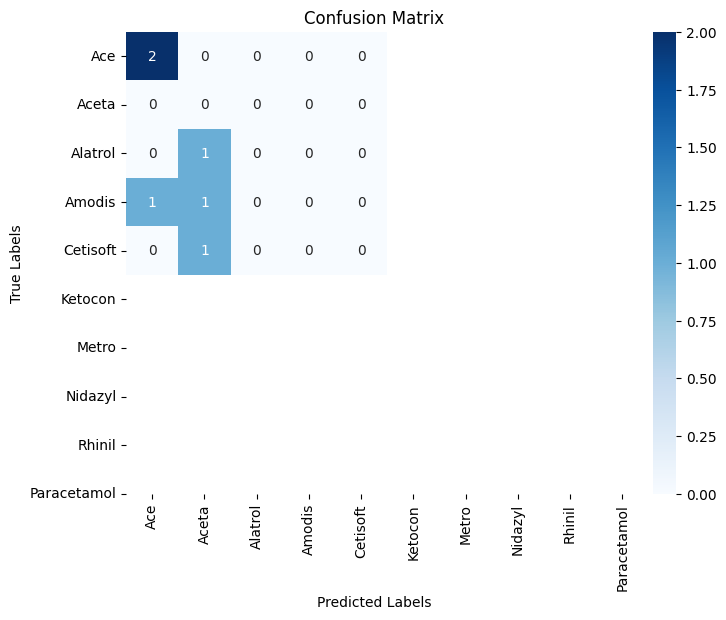

In [62]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Example: Replace these with your actual labels
y_true = [0, 100, 200, 20, 0, 100]  # True labels
y_pred = [0, 0, 2, 2, 0, 2]  # Predicted labels

# Define class names (update based on your dataset)
class_names = ['Ace', 'Aceta', 'Alatrol', 'Amodis',
           'Cetisoft', 'Ketocon', 'Metro', 'Nidazyl', 'Rhinil', 'Paracetamol']

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()


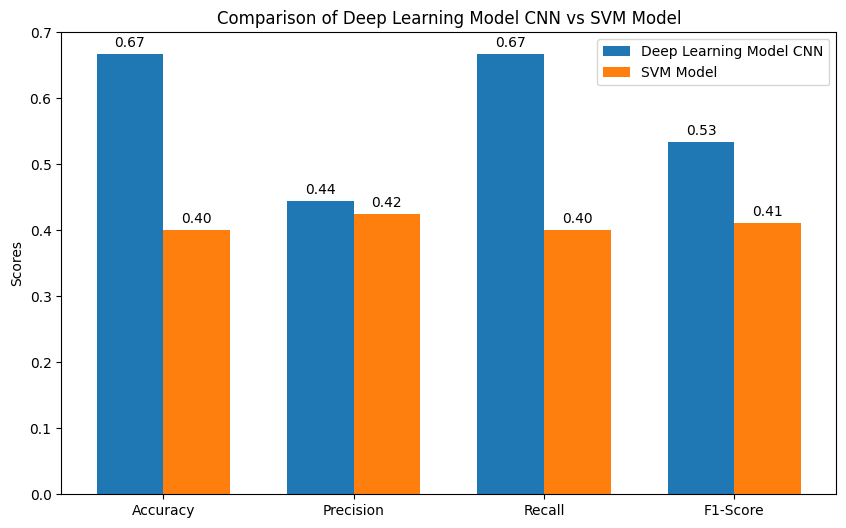

Comparison graph saved to: model_comparison_graph.png


In [63]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

# Assume you have y_true and y_pred from your deep learning model
# Replace with your actual values
y_true = [0, 1, 2, 2, 0, 1]
y_pred_deep = [0, 0, 2, 2, 0, 2]

# Step 1: Calculate metrics for your deep learning model
metrics_deep = {
    "Accuracy": accuracy_score(y_true, y_pred_deep),
    "Precision": precision_score(y_true, y_pred_deep, average="weighted"),
    "Recall": recall_score(y_true, y_pred_deep, average="weighted"),
    "F1-Score": f1_score(y_true, y_pred_deep, average="weighted")
}

# Step 2: Train an SVM model
# For this example, assume X_train, y_train, X_test, and y_test are already defined
# Replace with your actual data
X_train = np.random.rand(100, 10)  # Random training features
y_train = np.random.randint(0, 3, 100)  # Random training labels
X_test = np.random.rand(20, 10)    # Random testing features
y_test = np.random.randint(0, 3, 20)  # Random testing labels

# Standardize the data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train the SVM model
svm_model = SVC(kernel="linear", random_state=42)
svm_model.fit(X_train, y_train)

# Predict using the SVM model
y_pred_svm = svm_model.predict(X_test)

# Step 3: Calculate metrics for the SVM model
metrics_svm = {
    "Accuracy": accuracy_score(y_test, y_pred_svm),
    "Precision": precision_score(y_test, y_pred_svm, average="weighted"),
    "Recall": recall_score(y_test, y_pred_svm, average="weighted"),
    "F1-Score": f1_score(y_test, y_pred_svm, average="weighted")
}

# Step 4: Plot comparison graph
labels = metrics_deep.keys()
deep_values = metrics_deep.values()
svm_values = metrics_svm.values()

x = np.arange(len(labels))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, deep_values, width, label="Deep Learning Model CNN")
rects2 = ax.bar(x + width/2, svm_values, width, label="SVM Model")

# Add labels, title, and legend
ax.set_ylabel("Scores")
ax.set_title("Comparison of Deep Learning Model CNN vs SVM Model")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

# Add values above bars
def add_values(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f"{height:.2f}", xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points", ha="center", va="bottom")

add_values(rects1)
add_values(rects2)

# Save the plot
output_path = "model_comparison_graph.png"
plt.savefig(output_path)
plt.show()

print(f"Comparison graph saved to: {output_path}")
